## Lasso

##### Notes

The alpha parameter in Lasso regression controls the strength of the L1 regularization penalty.

##### Model

train 1992-03-31 to 2014-12-31  (92, 22)
test  2015-03-31 to 2025-12-31  (44, 22)
best params: {'lasso__alpha': np.float64(0.02592943797404667)}
best CV root_mean_squared_error: 0.3454


,full-training weight,mean across folds,sd across folds,share of folds used,sign flips
feature,,,,,
co_other_cons_L1,0.436032,0.194936,0.152526,1.0,False
emp_constr_L1,-0.058183,-0.023956,0.025173,0.6,False
hours_mfg_L1,-0.050287,-0.014891,0.021052,0.4,False
emp_pt_econ_L1,0.020198,0.003657,0.008101,0.4,False
house_cs10_L1,-0.017215,0.012684,0.035251,0.6,True
stk_vix_L1,0.004832,0.002564,0.005734,0.2,False
emp_info_L2,-0.000000,0.000000,0.000000,0.0,False
emp_info_L1,-0.000000,-0.012717,0.018053,0.6,False
emp_constr_L2,-0.000000,-0.005085,0.011371,0.2,False


recorded 'Lasso' -> /workspaces/DX799-O1/model_data/results


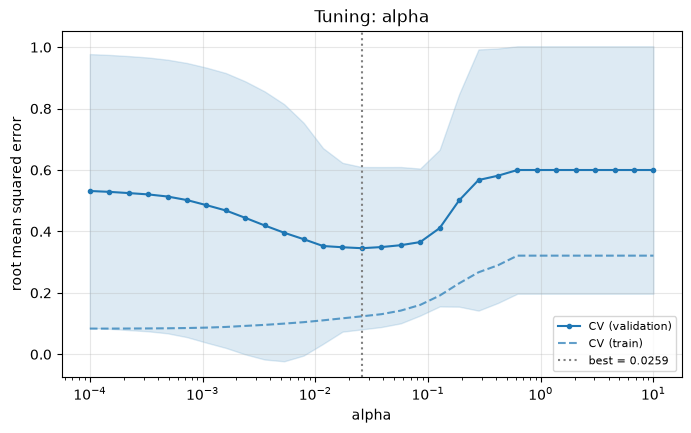

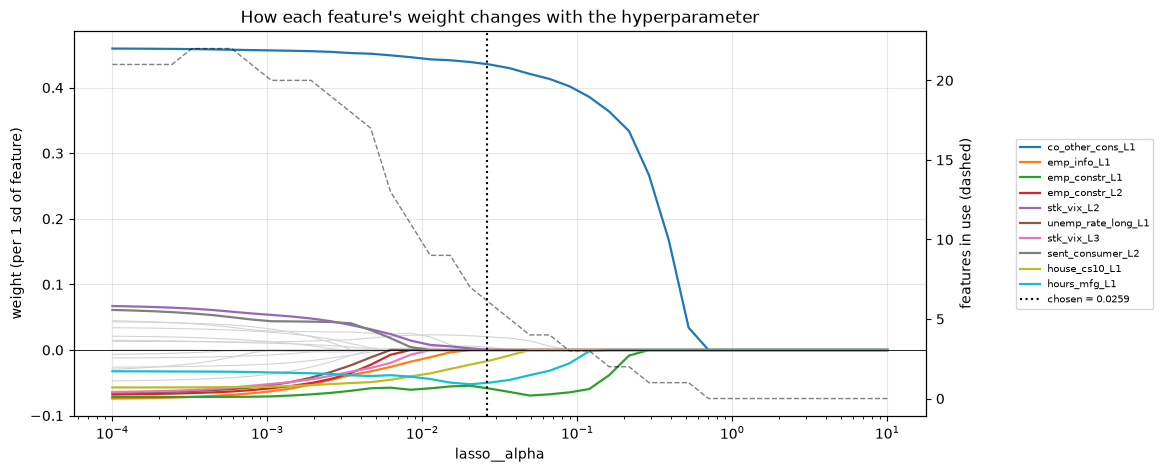

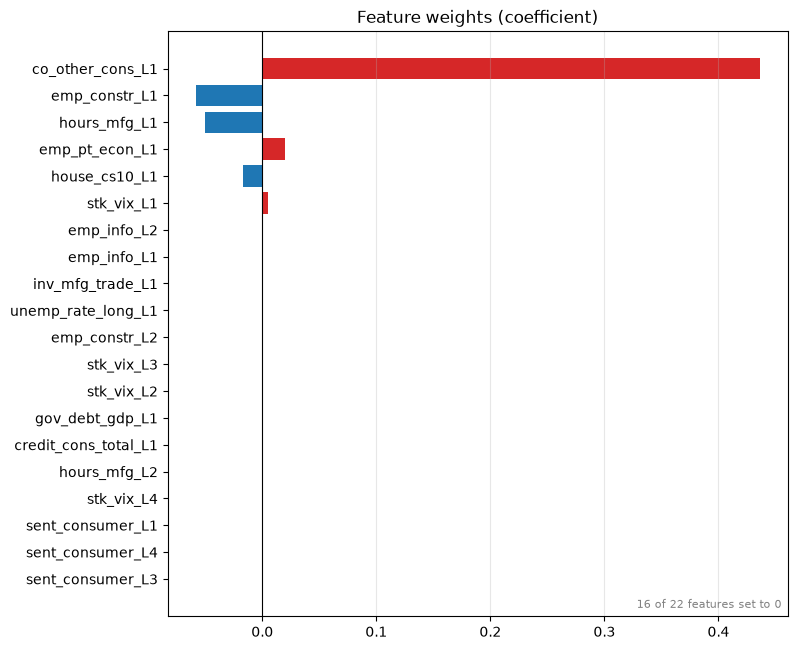

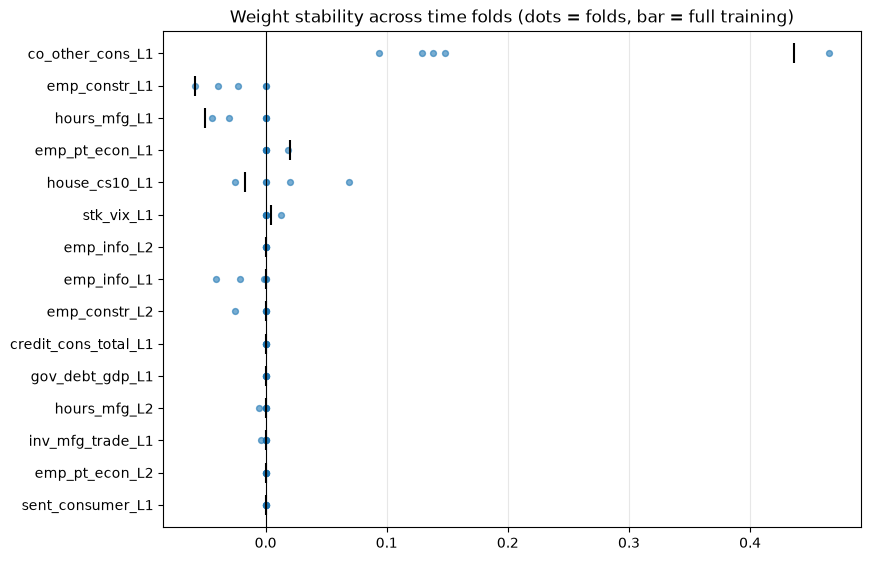

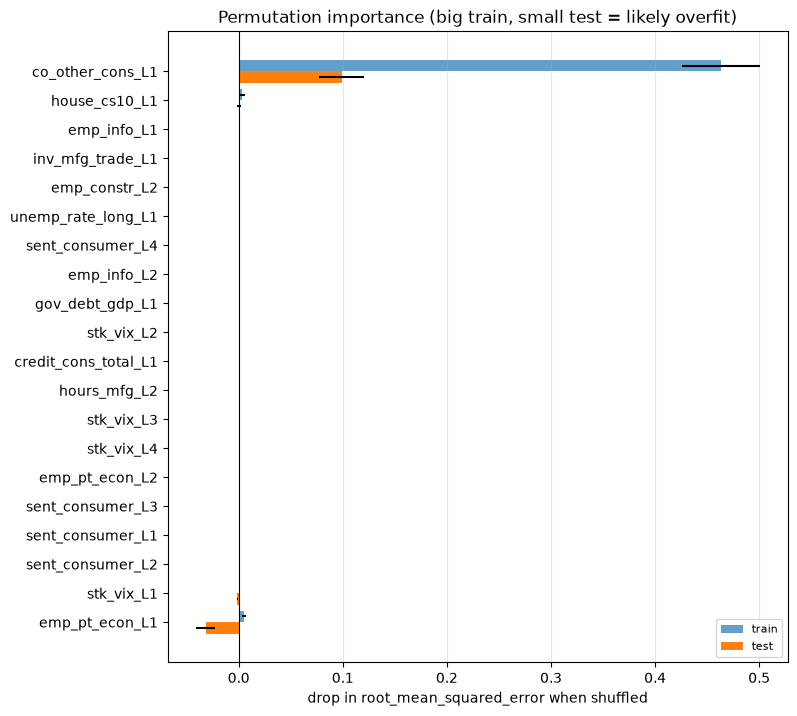

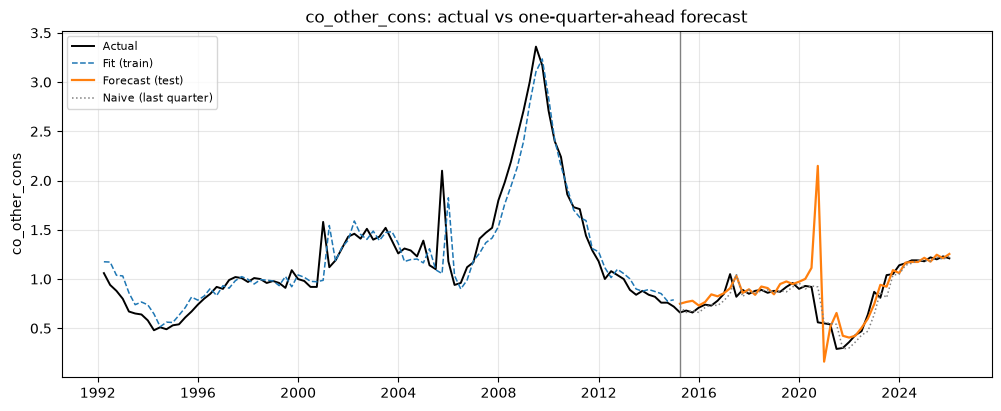

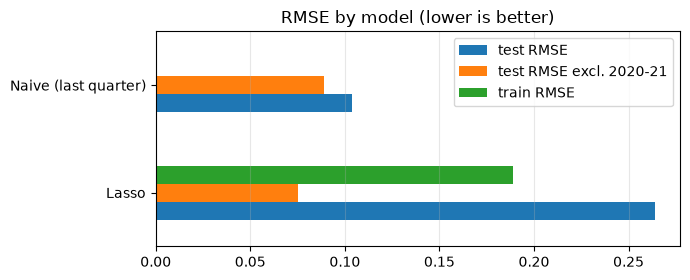

<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

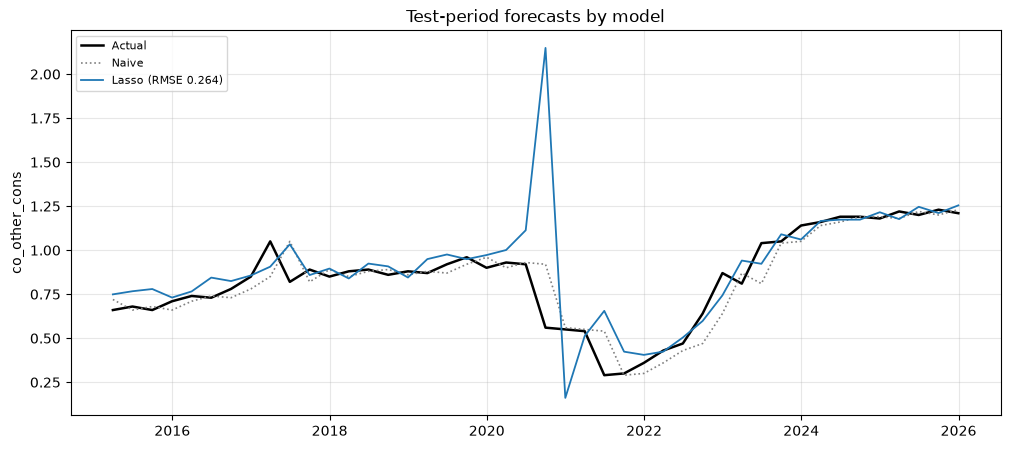

In [1]:
from prep import *
from sklearn.linear_model import Lasso

X_train, X_test, y_train, y_test, meta = load_model_data()

# 1) build + tune (grid lives in the notebook)
pipe = make_pipeline(*preprocess(scale=True), Lasso(max_iter=50_000))
grid = {"lasso__alpha": np.logspace(-4, 1, 30)}
search = tune(pipe, grid, X_train, y_train)
best  = search.best_estimator_
alpha = search.best_params_["lasso__alpha"]

# 2) see how the hyperparameter changes performance
tuning_table(search)
plot_tuning(search, "lasso__alpha")

# ---------- 4. How alpha changed each feature's weight ----------
path = weight_path(pipe, "lasso__alpha", np.logspace(-4, 1, 40), X_train, y_train)
plot_weight_path(path, best=alpha)

# ---------- 5. What the chosen model put on each feature ----------
feature_weights(best, X_train)                     # per lagged feature (0 = dropped)
feature_weights(best, X_train, by_variable=True)   # lags added up per variable
plot_feature_weights(best, X_train)

# ---------- 6. Overfitting checks ----------
W, stability = weight_stability(best, X_train, y_train)
display(stability)
plot_weight_stability(W)

perm = permutation_table(best, X_train, y_train, X_test, y_test)
plot_permutation(perm)

# 3) score the best model, look at it, save it for the final comparison
#best = search.best_estimator_
score(best, X_train, X_test, y_train, y_test)
plot_forecast(best, X_train, X_test, y_train, y_test)
record("Lasso", best, X_train, X_test, y_train, y_test, search=search,
       notes=f"alpha={alpha:.3g}")

# 4) any notebook (or a final one): compare every recorded model
compare()
plot_forecasts()

##### Export CSV 

In [2]:
export_predictions(best, X_train, X_test, y_train, y_test, name="Lasso")

saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Lasso_predictions.csv


,set,actual,predicted,error (pred - actual),abs error,naive (last quarter)
date,,,,,,
1992-03-31,train,1.06,1.175192,0.115192,0.115192,1.05
1992-06-30,train,0.94,1.172256,0.232256,0.232256,1.06
1992-09-30,train,0.88,1.038267,0.158267,0.158267,0.94
1992-12-31,train,0.80,1.031249,0.231249,0.231249,0.88
1993-03-31,train,0.67,0.860514,0.190514,0.190514,0.80
...,...,...,...,...,...,...
2024-12-31,test,1.18,1.215491,0.035491,0.035491,1.19
2025-03-31,test,1.22,1.176509,-0.043491,0.043491,1.18
2025-06-30,test,1.20,1.246390,0.046390,0.046390,1.22
